librerias

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random
from matplotlib.colors import ListedColormap
import pandas as pd 

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import os
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

creacion de centroides

In [98]:
n_centroides = np.random.randint(1, 21)

print("Número de centroides:", n_centroides)

blob_centers = []
while len(blob_centers) < n_centroides:
    candidate = np.random.uniform(-10, 10, size=2)
    if all(np.linalg.norm(candidate - center) > 4 for center in blob_centers):
        blob_centers.append(candidate)

blob_centers = np.array(blob_centers)
blob_std = np.random.uniform(
    0.3,
    1.0,
    size=n_centroides
)

puntos_por_centroide = np.random.randint(
    100,
    501,
    size=n_centroides
)

X_lista = []
y_lista = []

for i in range(n_centroides):

    X_i, y_i = make_blobs(
        n_samples=puntos_por_centroide[i],
        centers=[blob_centers[i]],
        cluster_std=blob_std[i],
        random_state=42 + i
    )

    X_lista.append(X_i)
    y_lista.append(y_i + i)


X = np.vstack(X_lista)
y = np.concatenate(y_lista)



print(f"Se generaron {n_centroides}")

print("Coordenadas de los centroides:")
print(blob_centers)
print("Desviaciones estándar de los centroides:")
print(blob_std)
print("Cantidad total de puntos:", len(X))
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

print("\nPuntos por centroide:")
print(np.bincount(y))


Número de centroides: 12
Se generaron 12
Coordenadas de los centroides:
[[-2.01226937  2.36369829]
 [-3.56782348 -9.46069387]
 [-7.53053369  2.0543109 ]
 [-2.00158574 -4.94127235]
 [ 5.38665384  2.68296387]
 [ 5.61082877 -1.90676646]
 [-5.89912155  9.37935852]
 [ 6.54225329  6.89587425]
 [ 6.24446132 -9.34533425]
 [-5.82459686 -2.01439505]
 [ 3.4223201   9.8524128 ]
 [-1.69344661  6.9052096 ]]
Desviaciones estándar de los centroides:
[0.96091732 0.95298704 0.50017678 0.31457345 0.58947669 0.82958275
 0.46707635 0.97226903 0.42281786 0.61233078 0.82523544 0.37828355]
Cantidad total de puntos: 3419
Forma de X: (3419, 2)
Forma de y: (3419,)

Puntos por centroide:
[133 467 199 215 297 481 148 258 105 220 481 415]


In [99]:
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

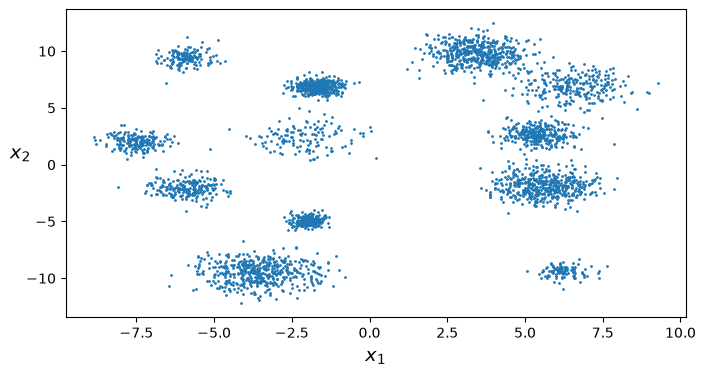

In [100]:
plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.show()

aplicacion de k-mans

In [101]:
from sklearn.cluster import KMeans
k = len(blob_centers)
kmeans = KMeans(n_clusters=k, random_state=42)
y_pred = kmeans.fit_predict(X)
y_pred   

array([11, 11, 11, ...,  2,  2,  2], shape=(3419,), dtype=int32)

In [ ]:
distancias = kmeans.transform(X)

cercanos = {} 

for i in range(k):
    # ordena todos los puntos por su distancia al centroide i y toma los 5 primeros
    idx = np.argsort(distancias[:, i])[:5]
    cercanos[i] = idx

    print(f"Centroide {i}: ({kmeans.cluster_centers_[i, 0]:.2f}, {kmeans.cluster_centers_[i, 1]:.2f})"
          f"  |  puntos en el cluster: {np.sum(y_pred == i)}")
    for j in idx:
        print(f"    punto {j:5d} -> ({X[j, 0]:7.2f}, {X[j, 1]:7.2f})   distancia = {distancias[j, i]:.4f}")

Centroide 0: (5.42, 2.65)  |  puntos en el cluster: 302
    punto  1046 -> (   5.43,    2.62)   distancia = 0.0301
    punto  1257 -> (   5.45,    2.67)   distancia = 0.0322
    punto  1305 -> (   5.40,    2.62)   distancia = 0.0378
    punto  1031 -> (   5.38,    2.63)   distancia = 0.0496
    punto  1017 -> (   5.36,    2.64)   distancia = 0.0592
Centroide 1: (-5.87, -2.06)  |  puntos en el cluster: 220
    punto  2465 -> (  -5.89,   -2.15)   distancia = 0.0897
    punto  2505 -> (  -5.89,   -2.15)   distancia = 0.0913
    punto  2497 -> (  -5.95,   -1.99)   distancia = 0.1038
    punto  2494 -> (  -5.76,   -2.04)   distancia = 0.1078
    punto  2314 -> (  -5.85,   -2.18)   distancia = 0.1210
Centroide 2: (-1.68, 6.87)  |  puntos en el cluster: 418
    punto  3134 -> (  -1.65,    6.90)   distancia = 0.0396
    punto  3276 -> (  -1.68,    6.91)   distancia = 0.0471
    punto  3238 -> (  -1.71,    6.83)   distancia = 0.0508
    punto  3008 -> (  -1.72,    6.90)   distancia = 0.0521
   

In [103]:
centroides_kmeans = kmeans.cluster_centers_

print("Centroides encontrados:")
print(centroides_kmeans)

Centroides encontrados:
[[ 5.42247185  2.65266913]
 [-5.86992999 -2.06045903]
 [-1.67939617  6.86619947]
 [ 3.4450329   9.83418015]
 [-3.55324079 -9.50228108]
 [ 5.61095671 -1.87110385]
 [-7.4782969   2.02467246]
 [ 6.55942589  6.89021653]
 [-5.91380243  9.41180879]
 [ 6.24048455 -9.39536326]
 [-2.01930843 -4.97257279]
 [-2.09045648  2.36848617]]


In [104]:
print("\nPuntos por centroide:")
print(np.bincount(y_pred))


Puntos por centroide:
[302 220 418 481 464 478 200 256 148 105 218 129]


In [105]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=10, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    k = clusterer.n_clusters                                          # <-- NUEVO
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    niveles = np.arange(k + 1) - 0.5                                  # <-- NUEVO: un nivel por cluster
    cmap = ListedColormap(plt.cm.tab20(np.linspace(0, 1, 20))[:k])    # <-- NUEVO: k colores distintos (Pastel2 solo tiene 8)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                 levels=niveles, cmap=cmap, alpha=0.5)                # <-- CAMBIO: levels y cmap
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                levels=niveles, linewidths=1, colors='k')             # <-- CAMBIO: levels
    plot_data(X)
    
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)
        

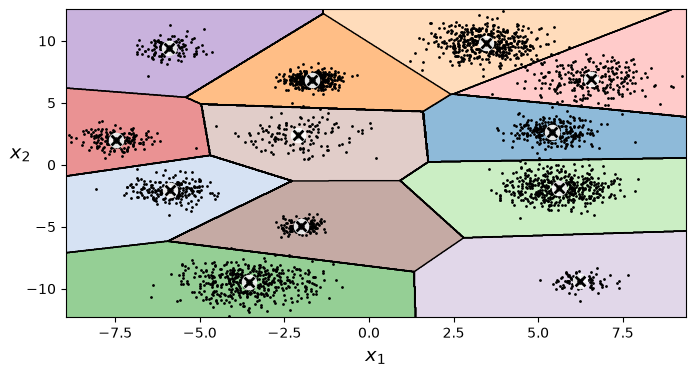

In [106]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

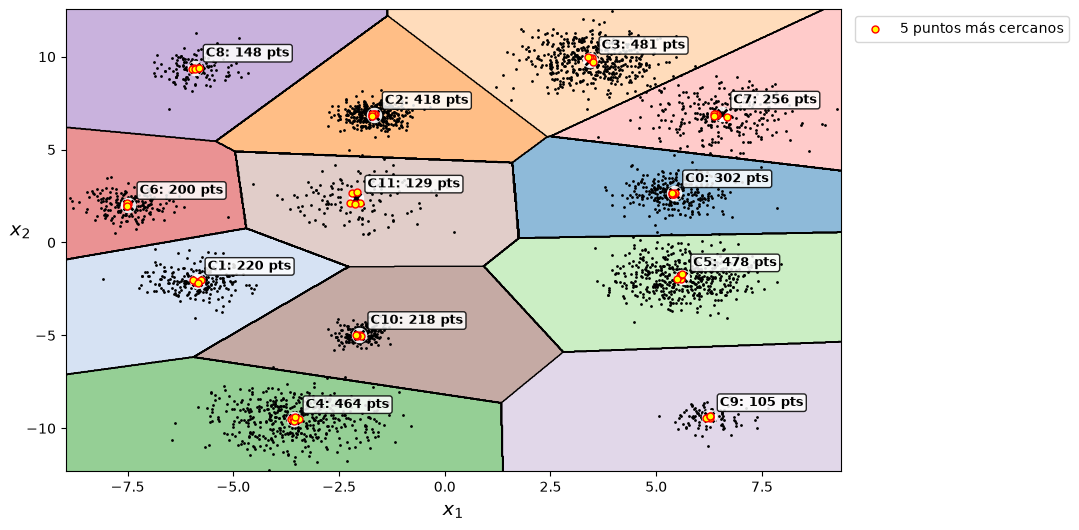

In [107]:
plt.figure(figsize=(10, 6))
plot_decision_boundaries(kmeans, X)

# los 5 puntos más cercanos de cada centroide
idx_cercanos = np.concatenate(list(cercanos.values()))
plt.scatter(X[idx_cercanos, 0], X[idx_cercanos, 1],
            c='yellow', edgecolors='red', s=25, linewidths=1,
            zorder=12, label='5 puntos más cercanos')   # zorder 12 > 11 de los centroides

# número de puntos de cada centroide
conteo = np.bincount(y_pred, minlength=k)
for i, (cx, cy) in enumerate(kmeans.cluster_centers_):
    plt.annotate(f"C{i}: {conteo[i]} pts", (cx, cy), xytext=(8, 8),
                 textcoords='offset points', fontsize=9, fontweight='bold', zorder=13,
                 bbox=dict(boxstyle='round,pad=0.2', fc='w', alpha=0.85))

plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.show()

In [3]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

NameError: name 'kmeans' is not defined

In [109]:
kmeans.transform(X_new)

array([[ 5.46160947,  7.13746493,  5.14784117,  8.55819083, 12.03860416,
         6.81676465,  7.4783376 ,  8.18170433,  9.48198127, 12.99222657,
         7.25908932,  2.1226847 ],
       [ 2.5088537 ,  9.75515174,  6.75104775,  7.84681037, 13.23810541,
         4.66931901, 10.47832595,  6.0484486 , 11.59270388, 11.84715341,
         8.59128794,  5.10377598],
       [ 8.42963053,  5.81762355,  4.08552234,  9.39385264, 12.51451587,
         9.89324154,  4.5832747 , 10.32067866,  7.04283583, 15.46064634,
         8.03266287,  1.10728458],
       [ 8.42385541,  5.38834712,  4.56154494,  9.76363905, 12.01502503,
         9.65686928,  4.50345194, 10.51934526,  7.50088964, 15.06274284,
         7.53665045,  0.91900234]])

punto 2: 3D


In [4]:
n_centroides = np.random.randint(1, 21)

print("Número de centroides:", n_centroides)

blob_centers = []
while len(blob_centers) < n_centroides:
    candidate = np.random.uniform(-10, 10, size=3)
    if all(np.linalg.norm(candidate - center) > 6.0 for center in blob_centers):
        blob_centers.append(candidate)

blob_centers = np.array(blob_centers)
blob_std = np.random.uniform(
    0.3,
    1.0,
    size=n_centroides
)

puntos_por_centroide = np.random.randint(
    100,
    501,
    size=n_centroides
)

X_lista = []
y_lista = []

for i in range(n_centroides):

    X_i, y_i = make_blobs(
        n_samples=puntos_por_centroide[i],
        centers=[blob_centers[i]],
        cluster_std=blob_std[i],
        random_state=42 + i
    )

    X_lista.append(X_i)
    y_lista.append(y_i + i)


X = np.vstack(X_lista)
y = np.concatenate(y_lista)



print(f"Se generaron {n_centroides}")

print("Coordenadas de los centroides:")
print(blob_centers)
print("Desviaciones estándar de los centroides:")
print(blob_std)
print("Cantidad total de puntos:", len(X))
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

print("\nPuntos por centroide:")
print(np.bincount(y))


Número de centroides: 20
Se generaron 20
Coordenadas de los centroides:
[[-3.03588842 -6.97406001  0.27864229]
 [-4.32055858  2.58737051  3.14079373]
 [ 6.37606216 -7.1518459   9.15166457]
 [-8.33918254 -0.99300842 -2.4920701 ]
 [-7.0078578  -3.78812544  9.59836802]
 [-7.98105353  8.60036363 -7.96260613]
 [ 1.78444528 -0.21058511 -2.5131925 ]
 [-9.16738779 -5.19913251 -7.05529883]
 [-1.65715647  5.75544757  9.21264054]
 [ 8.75192742  1.35493099  6.17233484]
 [ 0.13382044 -9.67382112 -9.52967099]
 [ 8.48499425  7.01057197 -8.87804102]
 [ 7.65042979  7.29820391  2.96684163]
 [-5.70131486  5.26497442 -2.64573719]
 [ 2.74175909 -9.46771799  4.51730523]
 [ 3.53630229  2.36925691 -8.68465735]
 [ 0.68656485 -1.82859799  7.83533441]
 [ 9.3735989  -8.15347383 -3.78558746]
 [ 0.39827016  6.07601684 -0.85662132]
 [-9.17302876  7.29030914  3.13224966]]
Desviaciones estándar de los centroides:
[0.5301045  0.45184097 0.58852213 0.95118564 0.79277306 0.87370856
 0.62597679 0.69979454 0.9488987  0.647

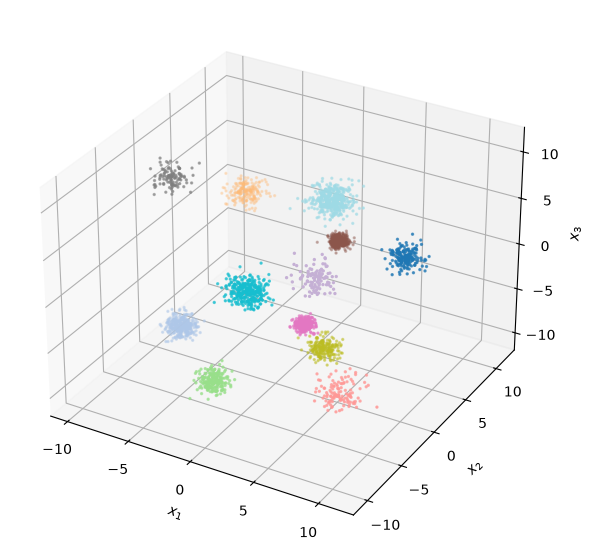

In [9]:
def plot_clusters_3d(X, y=None):
    ax = plt.figure(figsize=(9, 7)).add_subplot(projection='3d')
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, cmap='tab20', s=2)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")
    return ax

plot_clusters_3d(X, y)
plt.show()

In [10]:
k = len(blob_centers)
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)

print("Centroides encontrados:\n", kmeans.cluster_centers_)
print("\nPuntos por centroide:", np.bincount(y_pred))

Centroides encontrados:
 [[ 8.1787086  -9.19098238  8.99641592]
 [-0.18528039  9.88038741 -2.57663027]
 [ 3.04400954 -1.26076993 -3.25933201]
 [ 1.73046507  5.14984835  5.61882241]
 [-6.75617912 -1.71898548 -7.08791193]
 [-7.87756149  9.70688508  0.2115764 ]
 [-0.46701631 -7.9328024  -6.25676875]
 [-7.53673399 -1.34366005  8.64103043]
 [ 9.13036633  2.01653021  4.29009205]
 [ 0.18126594 -4.25515399  1.18705702]
 [ 2.47511143  2.64496347 -8.82612284]
 [ 7.63527288 -4.63403766 -6.42078309]]

Puntos por centroide: [107 499 290 441 330 200 214 108 191 329 210 125]


In [11]:
distancias = kmeans.transform(X)
cercanos = {}

for i in range(k):
    idx = np.argsort(distancias[:, i])[:5]
    cercanos[i] = idx

    cx, cy, cz = kmeans.cluster_centers_[i]
    print(f"Centroide {i}: ({cx:.2f}, {cy:.2f}, {cz:.2f})"
          f"  |  puntos en el cluster: {np.sum(y_pred == i)}")
    for j in idx:
        print(f"    punto {j:5d} -> ({X[j, 0]:7.2f}, {X[j, 1]:7.2f}, {X[j, 2]:7.2f})"
              f"   distancia = {distancias[j, i]:.4f}")

Centroide 0: (8.18, -9.19, 9.00)  |  puntos en el cluster: 107
    punto  1141 -> (   8.40,   -9.12,    8.97)   distancia = 0.2365
    punto  1103 -> (   8.12,   -9.40,    9.17)   distancia = 0.2756
    punto  1147 -> (   8.33,   -9.01,    9.19)   distancia = 0.3070
    punto  1165 -> (   8.03,   -9.08,    8.69)   distancia = 0.3633
    punto  1085 -> (   8.37,   -8.93,    9.16)   distancia = 0.3660
Centroide 1: (-0.19, 9.88, -2.58)  |  puntos en el cluster: 499
    punto  1239 -> (  -0.16,    9.92,   -2.63)   distancia = 0.0726
    punto  1319 -> (  -0.14,    9.80,   -2.62)   distancia = 0.1015
    punto  1236 -> (  -0.22,    9.80,   -2.65)   distancia = 0.1154
    punto  1335 -> (  -0.10,    9.84,   -2.50)   distancia = 0.1180
    punto  1295 -> (  -0.09,    9.84,   -2.51)   distancia = 0.1213
Centroide 2: (3.04, -1.26, -3.26)  |  puntos en el cluster: 290
    punto  1854 -> (   3.14,   -1.33,   -3.24)   distancia = 0.1149
    punto  1856 -> (   3.00,   -1.16,   -3.20)   distancia = 

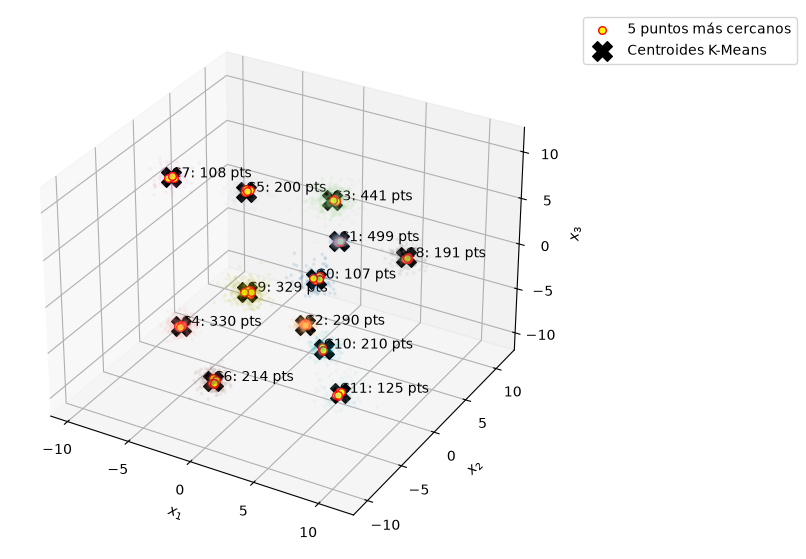

In [12]:
conteo = np.bincount(y_pred, minlength=k)
centros_km = kmeans.cluster_centers_

ax = plt.figure(figsize=(10, 7)).add_subplot(projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y_pred, cmap='tab20', s=3, alpha=0.3)

idx_cercanos = np.concatenate(list(cercanos.values()))
ax.scatter(X[idx_cercanos, 0], X[idx_cercanos, 1], X[idx_cercanos, 2],
           c='yellow', edgecolors='red', s=30, depthshade=False, label='5 puntos más cercanos')

ax.scatter(centros_km[:, 0], centros_km[:, 1], centros_km[:, 2],
           marker='X', s=200, c='k', depthshade=False, label='Centroides K-Means')

for i in range(k):
    ax.text(centros_km[i, 0], centros_km[i, 1], centros_km[i, 2], f"C{i}: {conteo[i]} pts")

ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.show()

In [13]:
X_new = np.array([[0, 2, 1], [9,9,9], [-3, 3, 0], [-3, 2.5, 2]])
print(kmeans.predict(X_new))
print(kmeans.transform(X_new))

[3 8 3 3]
[[16.00225073  8.65604521  6.16770004  5.8523136  11.17546995 11.04869515
  12.31013243 11.2413419   9.70507951  6.26057498 10.15356315 12.54495394]
 [18.20951324 14.80414895 17.06014194  8.89393995 24.93942141 19.04174776
  24.68021855 19.50855538  8.42431473 17.73446519 20.01827455 20.62886362]
 [18.82867698  7.86774434  8.08130292  7.65312439  9.30678253  8.29564212
  12.84870927 10.68254393 12.9041811   8.01041926 10.39246557 14.58128992]
 [17.62363273  9.12898184  8.85065054  6.51880907 10.70041416  8.88415768
  13.54376618  8.91397571 12.35411073  7.51088775 12.13271591 15.32687543]]


punto 3: con dt 


carga del dt


In [ ]:
df = pd.read_csv("dt_lab7/fashion-mnist_test.csv")
print("Con label:", df.shape) 

df_emnist = df.drop(columns="label") 
del df 
print("Sin label:", df_emnist.shape)
df_emnist.head()

Con label: (10000, 785)
Sin label: (10000, 784)


,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,9,8,0,...,103,87,56,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,14,53,99,17,...,0,0,0,0,63,53,31,0,0,0
3,0,0,0,0,0,0,0,0,0,161,...,137,126,140,0,133,224,222,56,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


division del dt

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(df_emnist, random_state=42)  
X_test = X_test[:40]
print(X_train.shape, X_test.shape)

(7500, 784) (40, 784)


normalizacion

In [5]:
X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

# encontrando el numero optimo de grupos

Calculando la métrica para diferentes números de clusters podemos encontrar el valor óptimo.

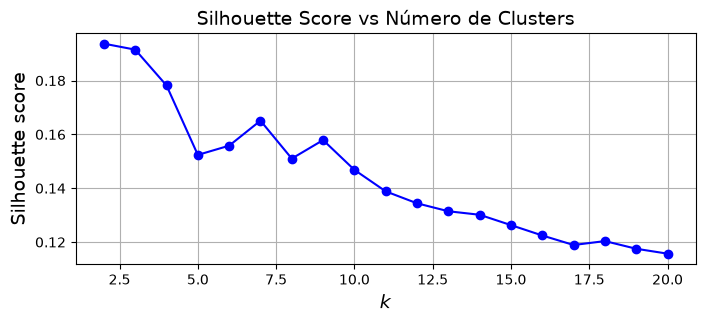

In [6]:
X = X_train.values 
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

max_k = 20 # no más de los centros generados
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]
# Generar eje x para k de 2 hasta max_k
ks = list(range(2, max_k + 1))

# plt.figure(figsize=(8, 3))
# plt.plot(ks, silhouette_scores, "bo-")
# # plt.plot(range(2, 10), silhouette_scores, "bo-")
# plt.xlabel("$k$", fontsize=14)
# plt.ylabel("Silhouette score", fontsize=14)
# plt.axis([1.8, 8.5, 0.55, 0.7])
# plt.show()

plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

diagramas de silueta

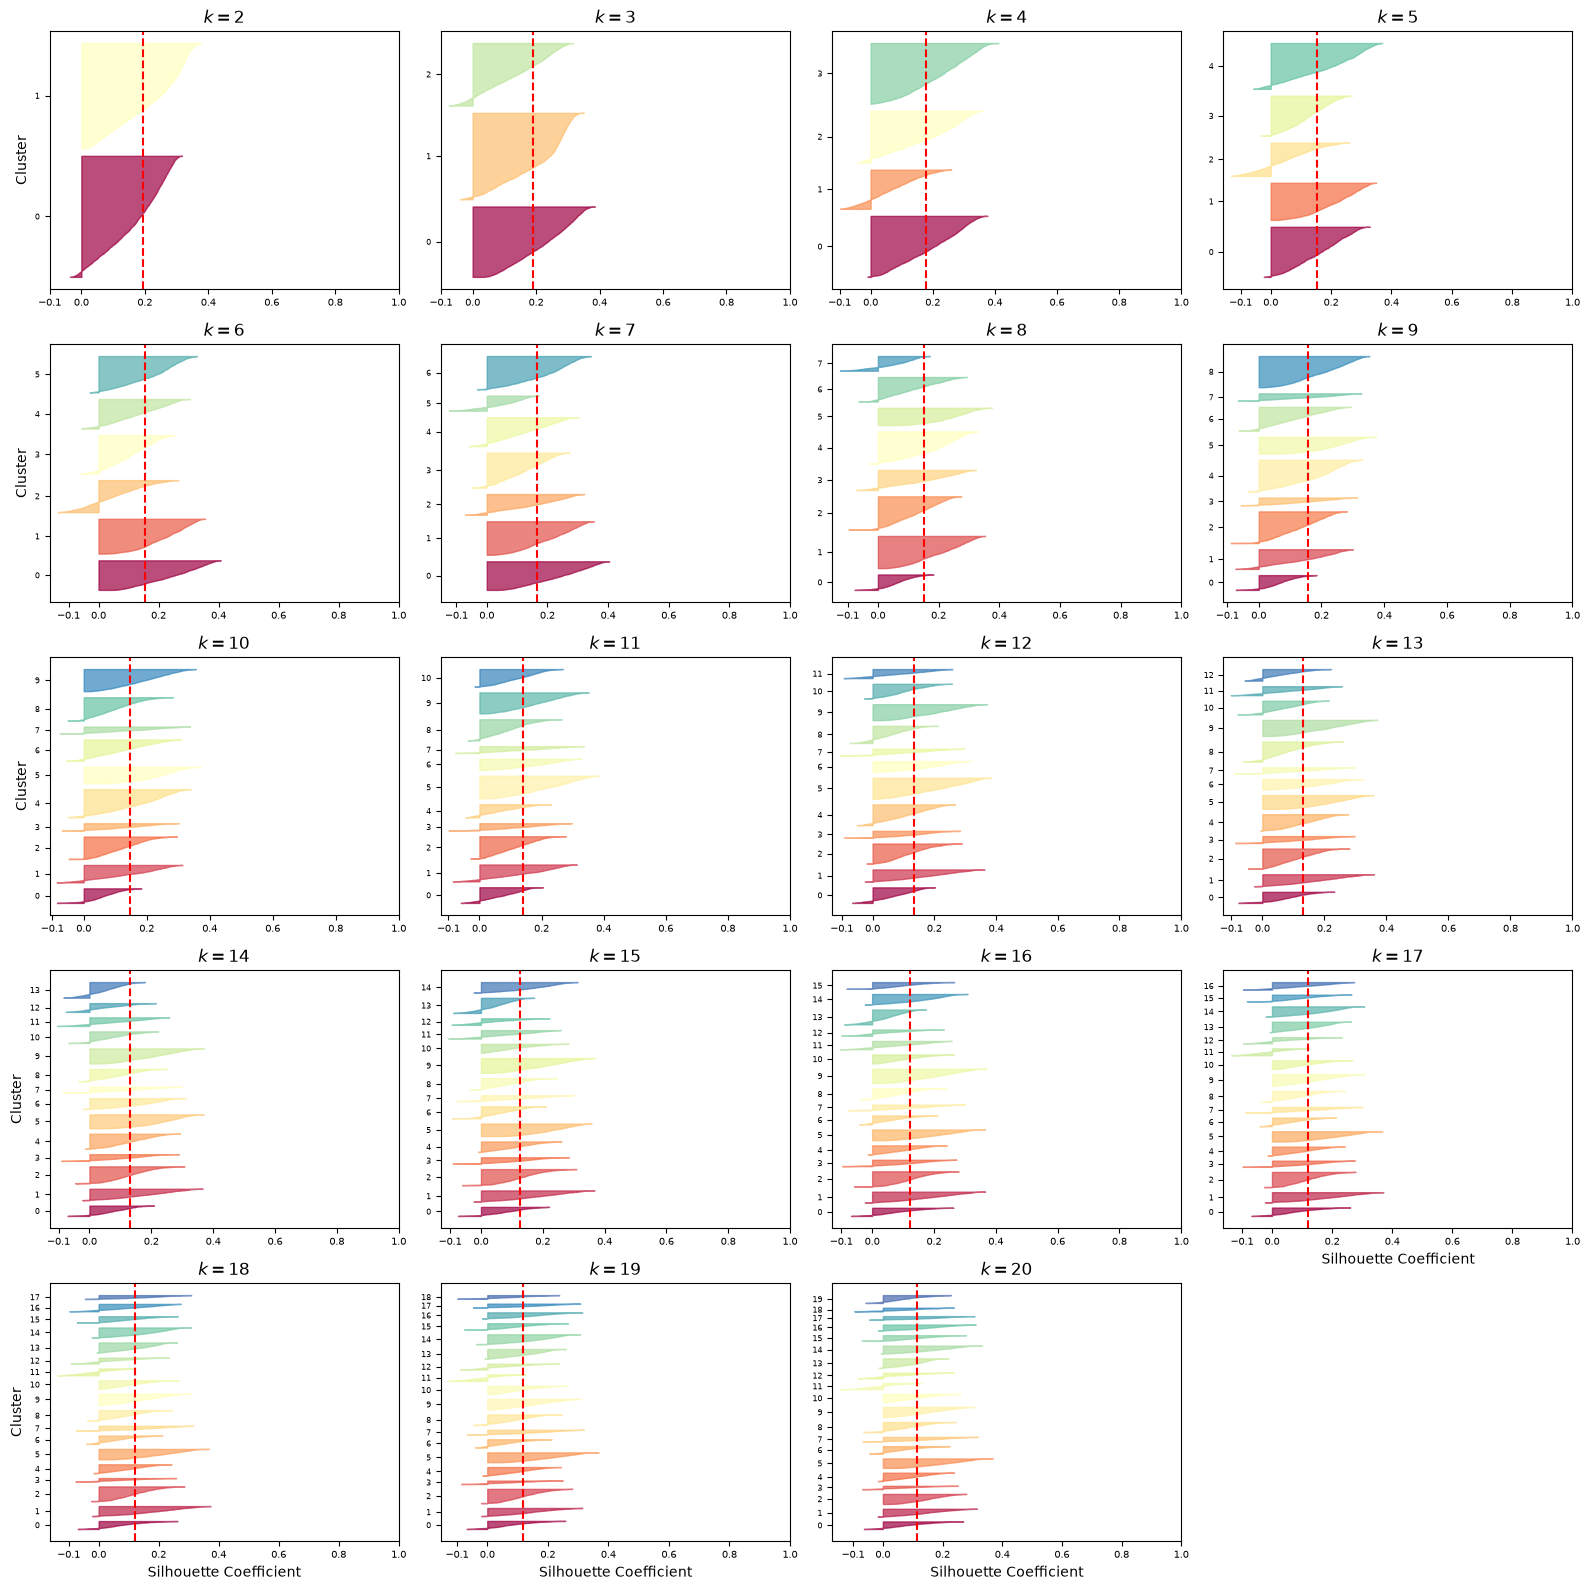

In [7]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

valid_ks = ks                         
n_cols = 4                 
n_rows = int(np.ceil(len(valid_ks) / n_cols))   

plt.figure(figsize=(4 * n_cols, 3.2 * n_rows))  

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(n_rows, n_cols, plot_idx + 1) 

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.tick_params(axis='y', labelsize=6)                    

    if plot_idx % n_cols == 0:                                
        plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])      
    plt.tick_params(axis='x', labelsize=7)
    if plot_idx >= len(valid_ks) - n_cols:                   
        plt.xlabel("Silhouette Coefficient")

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=12)

plt.tight_layout()                    
plt.show()

creamos los grupos, esta ves crearemos 20 grupos, para evitar un mal agrupamiento

In [8]:
from sklearn.cluster import KMeans

k = 20
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)

print(X_digits_dist.shape)

(7500, 20)


In [9]:
print(X_digits_dist.shape)
print(X_digits_dist)

(7500, 20)
[[ 9.31649506 10.42862522  8.24523467 ...  9.28669829 10.53793846
   7.78952108]
 [13.34236673 13.53483175 13.30756481 ... 10.59236022 11.42623142
  11.14403472]
 [ 6.40447281 12.27849945  8.05402014 ... 12.39391844 13.02473269
   7.83789171]
 ...
 [13.46821968 13.83974873 13.40689389 ... 11.32717557 11.41169841
  11.22893819]
 [13.52936516 12.38904952 12.75182064 ... 10.22857023  7.12777236
  11.84671129]
 [ 9.63243755  8.56916989  7.3829313  ... 10.84201515 12.34858827
   9.43652661]]


In [10]:
idxs = np.argmin(X_digits_dist, axis=0)
X_representative_digits = X_train.values[idxs]

In [11]:
print(X_representative_digits.shape)
print(X_representative_digits)

(20, 784)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


graficacion de las imagenes mas representativas

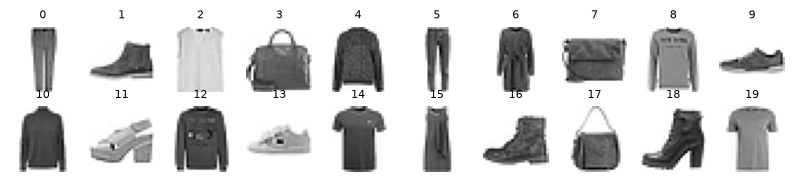

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for index, X_representative_digit in enumerate(X_representative_digits):
  plt.subplot(5, 10, index+1)
  plt.imshow(X_representative_digit.reshape(28,28), cmap="binary")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

etiquetamos esas 20 imagenes representativas

In [13]:
y_representative_digits = np.array([
    "pantalon", "bota de tobillo", "camiseta", "bolsas", "abrigo", "pantalon", "vestido", "bolsas","jersey", "zapatilla", "jersey", "sandalia", "jersey", "zapatilla", "camiseta", "vestido", "bota de tobillo", "bolsas", "bota de tobillo", "camiseta" 
])
print(len(y_representative_digits))

20


graficamos nuestras 40 variables de test

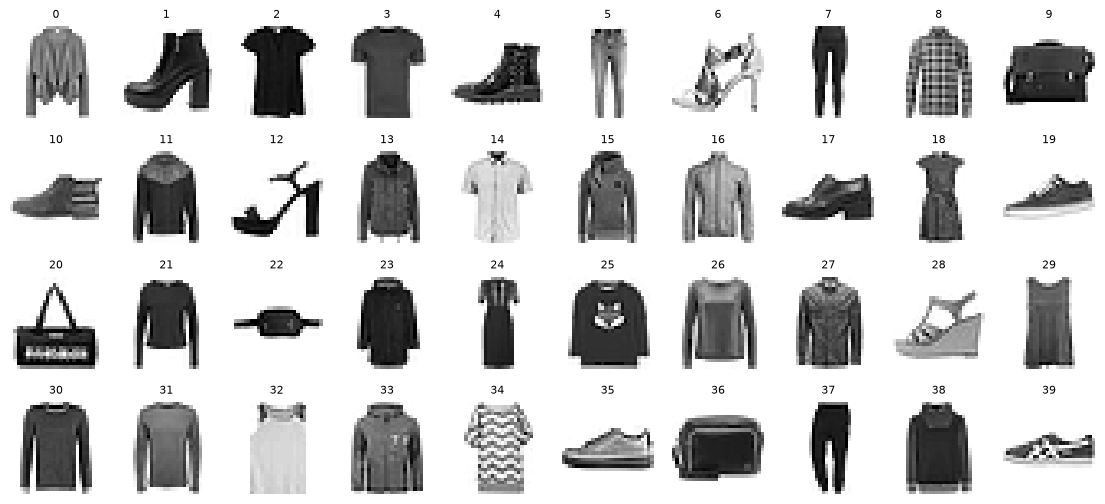

In [14]:
plt.figure(figsize=(14, 16))
for index, img in enumerate(X_test.values):
  plt.subplot(10, 10, index+1)
  plt.imshow(img.reshape(28,28), cmap="binary")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

las etiquetamos para poer ver la precicion del modelo

In [15]:
y_test = np.array([
    "jersey", "bota de tobillo", "camiseta", "camiseta", "bota de tobillo", "pantalon", "sandalia", "pantalon", "camiseta", "bolsas", "zapatilla", "abrigo", "sandalia", "abrigo", "camiseta", "jersey", "jersey", "zapatilla", "vestido", "zapatilla", "bolsas", "jersey", "bolsas", "abrigo", "vestido", "jersey", "jersey", "jersey", "sandalia", "vestido", "jersey", "jersey", "camiseta", "abrigo", "jersey", "zapatilla", "bolsas", "pantalon", "abrigo", "zapatilla"
])
print(len(y_test))

40


aqui realizamos la regresion con los valores de las imagenes repreestativas de cada grupo

In [16]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg2.fit(X_representative_digits, y_representative_digits)
log_reg2.score(X_test, y_test)

CPU times: total: 219 ms
Wall time: 213 ms


c:\Users\USUARIO\Desktop\ia_davalos\practicas\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


0.775

propagamos las etiquetas para otras imagenes de sus respectivos grupos

In [18]:
y_train_propagated = np.empty(len(X_train), dtype=object) 
for i in range(k):
  y_train_propagated[kmeans.labels_==i] = y_representative_digits[i]

volvemos a realizar una regrecion pero con mas datos


In [19]:
log_reg3 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train[:1000], y_train_propagated[:1000])
log_reg3.score(X_test, y_test)

CPU times: total: 50.2 s
Wall time: 3.38 s


0.775

vemos como se agurparon los grupor ya que algunos tenian la misma etiqueta

In [20]:
for digito in np.unique(y_representative_digits):
    grupos = np.where(y_representative_digits == digito)[0]
    print(f"Dígito {digito}: grupos {grupos}")

Dígito abrigo: grupos [4]
Dígito bolsas: grupos [ 3  7 17]
Dígito bota de tobillo: grupos [ 1 16 18]
Dígito camiseta: grupos [ 2 14 19]
Dígito jersey: grupos [ 8 10 12]
Dígito pantalon: grupos [0 5]
Dígito sandalia: grupos [11]
Dígito vestido: grupos [ 6 15]
Dígito zapatilla: grupos [ 9 13]


# aprendizaje activo

imagenes donde duda el modelo

In [21]:
probas = log_reg3.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
sorted_ixs = np.argsort(labels)
labels[sorted_ixs[:10]]

array([0.6868476 , 0.68968907, 0.69145035, 0.70699704, 0.71757714,
       0.72435237, 0.72836337, 0.73793818, 0.74793298, 0.75337441])

vemos las imagenes donde duda

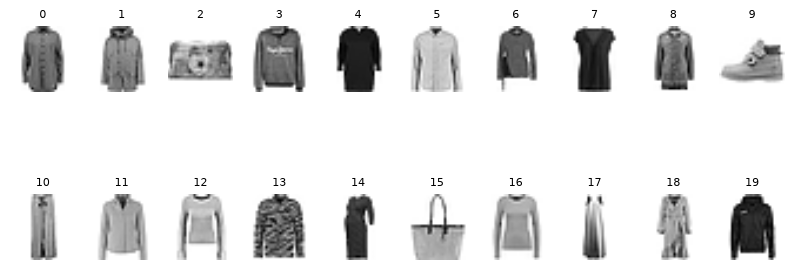

In [ ]:
n_consulta = 20                      

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1) 
    plt.imshow(img.reshape(28, 28), cmap="binary", interpolation="bilinear")
    plt.title(index, fontsize=8)                   
    plt.axis('off')
plt.show()

atiquetamos esas iamgenes para que el modelo las comprenda correctamente

In [23]:
y_lowest = np.array([
    "abrigo", "abrigo", "bolsas", "jersey", "jersey", "camiseta", "jersey", "camiseta", "abrigo", "bota de tobillo", "pantalón", "abrigo", "jersey", "abrigo", "vestido", "bolsas", "jersey", "vestido", "abrigo", "abrigo"
])
assert len(y_lowest) == n_consulta

In [24]:
print(y_train_propagated[:1000][sorted_ixs[:n_consulta]])

[np.str_('vestido') np.str_('camiseta') np.str_('bota de tobillo')
 np.str_('abrigo') np.str_('camiseta') np.str_('camiseta')
 np.str_('jersey') np.str_('camiseta') np.str_('vestido')
 np.str_('sandalia') np.str_('pantalon') np.str_('jersey')
 np.str_('camiseta') np.str_('abrigo') np.str_('vestido')
 np.str_('camiseta') np.str_('jersey') np.str_('pantalon')
 np.str_('pantalon') np.str_('jersey')]


corregimos las etiquetas

In [26]:
y_train2 = y_train_propagated[:1000].copy()
y_train2[sorted_ixs[:n_consulta]] = y_lowest

reentrenamos con las correciones

In [ ]:
log_reg5 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)   
%time log_reg5.fit(X_train[:1000], y_train2)
log_reg5.score(X_test, y_test)

CPU times: total: 12.7 s
Wall time: 911 ms


0.8

ronda de correcion 2

volvemos a ejecutar las mismas celdas pero ahora tomando la correccion anterior (cuantas veces quieras)

In [ ]:
ya_corregidas = np.zeros(1000, dtype=bool)
ya_corregidas[sorted_ixs[:n_consulta]] = True     

probas = log_reg5.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
labels[ya_corregidas] = 2           
sorted_ixs = np.argsort(labels)

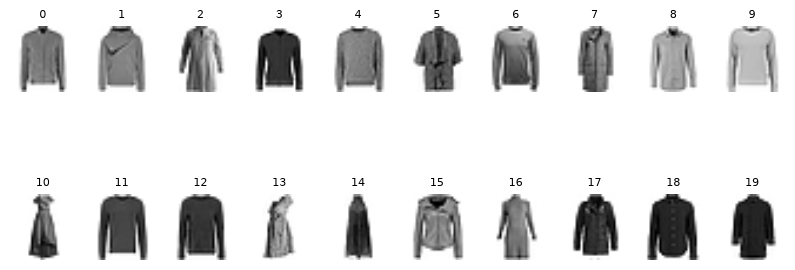

In [29]:
n_consulta = 20                                                  # <-- NUEVO: cuántas imágenes vas a etiquetar por ronda

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)    # <-- CAMBIO: filas calculadas (antes k // 10)
    plt.imshow(img.reshape(28, 28), cmap="binary", interpolation="bilinear")
    plt.title(index, fontsize=8)                                 # <-- NUEVO: número de cada imagen
    plt.axis('off')
plt.show()

In [30]:
y_lowest = np.array([
    "abrigo", "abrigo", "abrigo", "jersey", "jersey", "jersey", "jersey", "abrigo", "abrigo", "jersey", "vestido", "jersey", "jersey", "vestido", "vestido", "jersey", "abrigo", "abrigo", "abrigo", "abrigo"
])
assert len(y_lowest) == n_consulta

In [31]:
y_train3 = y_train2.copy()                               # parte de lo ya corregido
y_train3[sorted_ixs[:n_consulta]] = y_lowest             # y_lowest = tus nuevas etiquetas
log_reg6 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg6.fit(X_train[:1000], y_train3)
log_reg6.score(X_test, y_test)

0.8